In [1]:
import pandas as pd
import time

file = "SpectrumData_2021Y.xlsx"

sheets = ["wavelength", "darkcurrent", "trainSet", "testSetLowNoise"]
data = {}

for sheet in sheets:
    start = time.time()
    print(f"Loading {sheet}...", flush=True)

    data[sheet] = pd.read_excel(file, sheet_name=sheet)

    print(
        f"Loaded {sheet}: {data[sheet].shape} "
        f"in {time.time() - start:.1f} seconds",
        flush=True
    )

wavelength = data["wavelength"]
darkcurrent = data["darkcurrent"]
trainSet = data["trainSet"]
testSetLowNoise = data["testSetLowNoise"]

Loading wavelength...
Loaded wavelength: (224, 3) in 0.1 seconds
Loading darkcurrent...
Loaded darkcurrent: (640, 224) in 0.4 seconds
Loading trainSet...
Loaded trainSet: (50000, 227) in 36.8 seconds
Loading testSetLowNoise...
Loaded testSetLowNoise: (100000, 227) in 80.7 seconds


Preparing training spectra...

Clusters per category:
class_id
PE     12
PP     12
PET    12
PS     12
PVC    12

Training rows: 50,000
Spectral channels: 224
Spatial clusters: 60
Validation folds: 5

Training and tuning logistic regression...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best settings: {'C': 1}
Mean validation macro F1: 0.9875

Evaluating on testSetLowNoise...


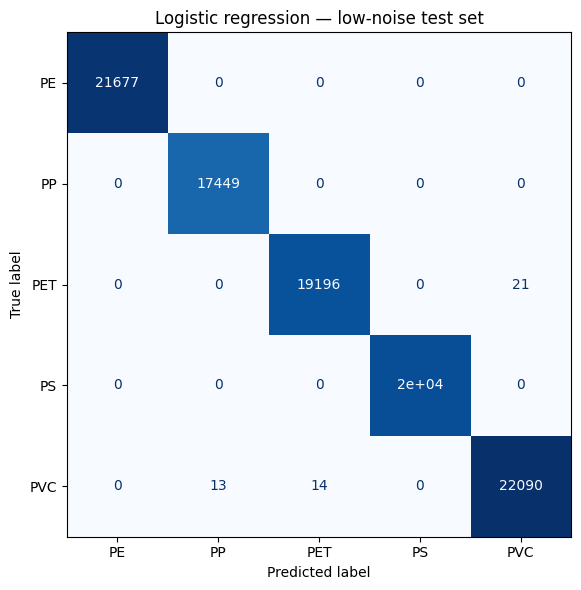


Test metrics:
test_accuracy: 0.9995
test_macro_precision: 0.9995
test_macro_recall: 0.9995
test_macro_f1: 0.9995

Results saved to: /Users/williamronan/PythonTools/HyperspectralPVCSort/results/logistic_regression


In [2]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import label
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# 1. Configuration
# ============================================================

RESULTS_DIR = Path("results") / "logistic_regression"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CHANNELS = [f"ch.{i}" for i in range(1, 225)]
CLASS_NAMES = {1: "PE", 2: "PP", 3: "PET", 4: "PS", 5: "PVC"}
CLASS_IDS = list(CLASS_NAMES)
RANDOM_STATE = 42

# ============================================================
# 2. Preprocessing
# ============================================================

wavelength_nm = (
    wavelength.set_index("channel")
    .loc[range(1, 225), "wavelength"]
    .to_numpy(dtype=float)
)

dark_values = darkcurrent[CHANNELS].to_numpy(dtype=float)

if not np.isfinite(dark_values).all():
    raise ValueError("Dark-current reference contains invalid values.")

dark_vector = dark_values.mean(axis=0)


def preprocess(frame):
    """Subtract mean dark current and normalize each spectrum to [0, 1]."""
    spectra = frame[CHANNELS].to_numpy(dtype=float)

    if not np.isfinite(spectra).all():
        raise ValueError("Spectra contain missing or non-finite values.")

    corrected = spectra - dark_vector
    row_min = corrected.min(axis=1, keepdims=True)
    row_range = np.ptp(corrected, axis=1, keepdims=True)

    if np.any(row_range == 0):
        raise ValueError("Constant spectra detected. Inspect before training.")

    return (corrected - row_min) / row_range


def get_labels(frame):
    values = pd.to_numeric(frame["class_id"], errors="raise").to_numpy()

    if not np.isin(values, CLASS_IDS).all():
        raise ValueError("Expected class labels 1–5.")

    return values.astype(int)


print("Preparing training spectra...", flush=True)

X_train = preprocess(trainSet)
y_train = get_labels(trainSet)

# ============================================================
# 3. Identify spatial clusters for validation
# ============================================================

coords = trainSet[
    ["coord_lateral", "coord_driving"]
].to_numpy(dtype=float)

if not np.isfinite(coords).all() or not (coords % 1 == 0).all():
    raise ValueError("Grouping requires valid integer coordinates.")

coords = coords.astype(int)
offsets = coords - coords.min(axis=0)

occupancy = np.zeros(
    (offsets[:, 1].max() + 1, offsets[:, 0].max() + 1),
    dtype=bool
)
occupancy[offsets[:, 1], offsets[:, 0]] = True

cluster_grid, cluster_count = label(
    occupancy,
    structure=np.ones((3, 3), dtype=int)
)
groups = cluster_grid[offsets[:, 1], offsets[:, 0]]

group_table = pd.DataFrame({
    "cluster": groups,
    "class_id": y_train
})

if group_table.groupby("cluster")["class_id"].nunique().gt(1).any():
    raise ValueError("Some clusters contain multiple categories.")

object_table = (
    group_table.drop_duplicates("cluster")
    .sort_values("cluster")
    .reset_index(drop=True)
)

groups_per_class = (
    object_table["class_id"]
    .value_counts()
    .reindex(CLASS_IDS, fill_value=0)
)

print("\nClusters per category:")
print(groups_per_class.rename(index=CLASS_NAMES).to_string())

n_splits = min(5, int(groups_per_class.min()))

if n_splits < 2:
    raise ValueError("Need at least two spatial clusters per category.")

# Same splitting procedure and seed as the voting model.
object_cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=RANDOM_STATE
)

folds = []
fold_records = []
validation_fold = np.full(len(trainSet), -1, dtype=int)

for fold_number, (fit_objects, val_objects) in enumerate(
    object_cv.split(
        object_table["cluster"],
        object_table["class_id"]
    ),
    start=1
):
    fit_groups = object_table.iloc[fit_objects]["cluster"].to_numpy()
    val_groups = object_table.iloc[val_objects]["cluster"].to_numpy()

    fit_indices = np.flatnonzero(np.isin(groups, fit_groups))
    val_indices = np.flatnonzero(np.isin(groups, val_groups))

    if np.intersect1d(fit_groups, val_groups).size:
        raise ValueError("A cluster appears on both sides of a fold.")

    for indices in [fit_indices, val_indices]:
        if set(np.unique(y_train[indices])) != set(CLASS_IDS):
            raise ValueError("A fold is missing a category.")

    folds.append((fit_indices, val_indices))
    validation_fold[val_indices] = fold_number

    for class_id in CLASS_IDS:
        fold_records.append({
            "fold": fold_number,
            "plastic": CLASS_NAMES[class_id],
            "training_clusters": int(
                (
                    object_table.iloc[fit_objects]["class_id"] == class_id
                ).sum()
            ),
            "validation_clusters": int(
                (
                    object_table.iloc[val_objects]["class_id"] == class_id
                ).sum()
            ),
            "training_rows": int(
                (y_train[fit_indices] == class_id).sum()
            ),
            "validation_rows": int(
                (y_train[val_indices] == class_id).sum()
            )
        })

pd.DataFrame(fold_records).to_csv(
    RESULTS_DIR / "validation_fold_summary.csv", index=False
)

pd.DataFrame({
    "row_position": np.arange(len(trainSet)),
    "cluster": groups,
    "class_id": y_train,
    "validation_fold": validation_fold
}).to_csv(
    RESULTS_DIR / "training_groups.csv", index=False
)

print(f"\nTraining rows: {len(X_train):,}")
print(f"Spectral channels: {X_train.shape[1]}")
print(f"Spatial clusters: {cluster_count}")
print(f"Validation folds: {n_splits}")

# ============================================================
# 4. Tune regularization using training/validation data
# ============================================================

model = LogisticRegression(
    class_weight="balanced",
    solver="lbfgs",
    max_iter=5000,
    random_state=RANDOM_STATE
)

search = GridSearchCV(
    estimator=model,
    param_grid={"C": [0.01, 0.1, 1, 10, 100]},
    scoring={
        "accuracy": "accuracy",
        "macro_precision": "precision_macro",
        "macro_recall": "recall_macro",
        "macro_f1": "f1_macro"
    },
    refit="macro_f1",
    cv=folds,
    n_jobs=-1,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

print("\nTraining and tuning logistic regression...", flush=True)
search.fit(X_train, y_train)

# Automatically refitted on the entire training set.
best_model = search.best_estimator_

pd.DataFrame(search.cv_results_).to_csv(
    RESULTS_DIR / "cross_validation_results.csv", index=False
)

print(f"\nBest settings: {search.best_params_}")
print(f"Mean validation macro F1: {search.best_score_:.4f}")

# ============================================================
# 5. Final evaluation on testSetLowNoise
# ============================================================

print("\nEvaluating on testSetLowNoise...", flush=True)

X_test = preprocess(testSetLowNoise)
y_test = get_labels(testSetLowNoise)

predictions = best_model.predict(X_test)
probabilities = best_model.predict_proba(X_test)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test,
    predictions,
    labels=CLASS_IDS,
    average="macro",
    zero_division=0
)

metrics = {
    "test_accuracy": float(accuracy_score(y_test, predictions)),
    "test_macro_precision": float(precision),
    "test_macro_recall": float(recall),
    "test_macro_f1": float(f1),
    "best_validation_macro_f1": float(search.best_score_),
    "best_C": float(search.best_params_["C"]),
    "validation_folds": n_splits,
    "training_clusters": int(cluster_count),
    "training_rows": len(X_train),
    "test_rows": len(X_test),
    "spectral_channels": len(CHANNELS)
}

with open(RESULTS_DIR / "metrics.json", "w") as handle:
    json.dump(metrics, handle, indent=2)

report = classification_report(
    y_test,
    predictions,
    labels=CLASS_IDS,
    target_names=list(CLASS_NAMES.values()),
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    RESULTS_DIR / "classification_report.csv"
)

prediction_table = pd.DataFrame({
    "row_position": np.arange(len(y_test)),
    "true_class": y_test,
    "predicted_class": predictions,
    "correct": predictions == y_test
})

for column, class_id in enumerate(best_model.classes_):
    prediction_table[f"probability_{CLASS_NAMES[class_id]}"] = (
        probabilities[:, column]
    )

prediction_table.to_csv(
    RESULTS_DIR / "test_predictions.csv", index=False
)

cm = confusion_matrix(y_test, predictions, labels=CLASS_IDS)

pd.DataFrame(
    cm,
    index=pd.Index(CLASS_NAMES.values(), name="true_category"),
    columns=pd.Index(CLASS_NAMES.values(), name="predicted_category")
).to_csv(RESULTS_DIR / "confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    cm,
    display_labels=list(CLASS_NAMES.values())
).plot(ax=ax, cmap="Blues", colorbar=False)

ax.set_title("Logistic regression — low-noise test set")
fig.tight_layout()
fig.savefig(
    RESULTS_DIR / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# ============================================================
# 6. Save channel weights and trained model
# ============================================================

weights_table = pd.DataFrame({
    "channel": CHANNELS,
    "wavelength_nm": wavelength_nm
})

for class_id, coefficients in zip(
    best_model.classes_, best_model.coef_
):
    weights_table[f"weight_{CLASS_NAMES[class_id]}"] = coefficients

weights_table.to_csv(
    RESULTS_DIR / "channel_weights.csv", index=False
)

pd.DataFrame({
    "plastic": [CLASS_NAMES[c] for c in best_model.classes_],
    "intercept": best_model.intercept_
}).to_csv(
    RESULTS_DIR / "class_intercepts.csv", index=False
)

joblib.dump(
    {
        "model": best_model,
        "dark_vector": dark_vector,
        "wavelength_nm": wavelength_nm,
        "channels": CHANNELS,
        "normalization": "per-spectrum min-max after dark subtraction",
        "class_names": CLASS_NAMES
    },
    RESULTS_DIR / "model_bundle.joblib"
)

print("\nTest metrics:")
for name in [
    "test_accuracy",
    "test_macro_precision",
    "test_macro_recall",
    "test_macro_f1"
]:
    print(f"{name}: {metrics[name]:.4f}")

print(f"\nResults saved to: {RESULTS_DIR.resolve()}")